# 🎯 True Tone SIH — Model Fine-Tuning Notebook

**Purpose:** Resume training / fine-tune the `AudioSpoofDetector` (CNN-BiLSTM-Attention) from the existing `best_audio_spoof_model.pt` checkpoint.

| Setting | Value |
|---|---|
| Compute | NVIDIA RTX 2050 (CUDA + AMP) |
| Data | ASVspoof 2019 LA cached `.pt` features on `D:/True Tone SIH/data/cached_features` |
| Checkpoint | `models/best_audio_spoof_model.pt` |

---

## 1 · Environment Setup & Imports

In [1]:
import os, sys, glob, time, io
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_curve, accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from tqdm.notebook import tqdm   # nice progress bars in Jupyter
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

# ── Resolve project root and add src/audio to path ──
NOTEBOOK_DIR = os.path.dirname(os.path.abspath('__file__'))
PROJECT_ROOT = os.path.abspath(os.path.join(NOTEBOOK_DIR, '..'))
AUDIO_SRC    = os.path.join(PROJECT_ROOT, 'src', 'audio')
sys.path.insert(0, AUDIO_SRC)

from model import AudioSpoofDetector
from features import extract_lfcc

print(f"Project root : {PROJECT_ROOT}")
print(f"Audio source : {AUDIO_SRC}")
print(f"PyTorch      : {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")
    print(f"VRAM         : {torch.cuda.get_device_properties(0).total_mem / 1024**3:.1f} GB")

Project root : C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih
Audio source : C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih\src\audio
PyTorch      : 2.14.0+cpu
CUDA available: False


## 2 · Configuration (edit these before running)

Adjust any hyperparameters here. The cell below is the **single source of truth** for the entire notebook.

In [2]:
# ═══════════════════════════════════════════════════════
# PATHS
# ═══════════════════════════════════════════════════════
TRAIN_CACHE_DIR = r"D:/True Tone SIH/data/cached_features/train"
DEV_CACHE_DIR   = r"D:/True Tone SIH/data/cached_features/dev"
CHECKPOINT_DIR  = os.path.join(PROJECT_ROOT, 'models')
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, 'best_audio_spoof_model.pt')

# ═══════════════════════════════════════════════════════
# HYPERPARAMETERS  (tune these!)
# ═══════════════════════════════════════════════════════
EPOCHS       = 10       # additional epochs to train
BATCH_SIZE   = 32       # fits comfortably in RTX 2050 4GB
LEARNING_RATE = 1e-4    # lower LR for fine-tuning (original was 3e-4)
WEIGHT_DECAY  = 1e-4    # AdamW regularization
POS_WEIGHT    = 0.25    # BCE class weight (spoof samples outnumber bonafide ~9:1)
GRAD_CLIP     = 5.0     # max gradient norm
SCHEDULER     = 'cosine'  # 'cosine' or 'step'
STEP_LR_DECAY = 0.5    # only used if SCHEDULER='step'
STEP_LR_EVERY = 5      # only used if SCHEDULER='step'

# ═══════════════════════════════════════════════════════
# MODEL ARCHITECTURE (must match checkpoint)
# ═══════════════════════════════════════════════════════
INPUT_DIM  = 60
HIDDEN_DIM = 128

print("✅ Configuration loaded.")
print(f"   Training for {EPOCHS} epochs, batch_size={BATCH_SIZE}, lr={LEARNING_RATE}")
print(f"   Checkpoint: {CHECKPOINT_PATH}")

✅ Configuration loaded.
   Training for 10 epochs, batch_size=32, lr=0.0001
   Checkpoint: C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih\models\best_audio_spoof_model.pt


## 3 · Load Cached Dataset

In [3]:
class CachedAudioDataset(Dataset):
    """Loads pre-cached LFCC (400, 60) tensor files from disk."""
    def __init__(self, cache_dir):
        self.files = sorted(glob.glob(os.path.join(cache_dir, '*.pt')))
        if not self.files:
            raise RuntimeError(f"No .pt files in {cache_dir}. Run preprocess_cache.py first!")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = torch.load(self.files[idx], weights_only=True)
        return data['feat'], torch.tensor(data['label'], dtype=torch.float32)


train_ds = CachedAudioDataset(TRAIN_CACHE_DIR)
dev_ds   = CachedAudioDataset(DEV_CACHE_DIR)

print(f"📂 Train samples: {len(train_ds):,}")
print(f"📂 Dev samples  : {len(dev_ds):,}")

# Count label distribution
train_labels = []
for i in range(min(len(train_ds), 500)):  # sample first 500 for speed
    _, lbl = train_ds[i]
    train_labels.append(int(lbl.item()))

n_bona = train_labels.count(0)
n_spoof = train_labels.count(1)
print(f"\n📊 Label distribution (sampled {len(train_labels)})")
print(f"   Bonafide (0): {n_bona} ({n_bona/len(train_labels)*100:.1f}%)")
print(f"   Spoof    (1): {n_spoof} ({n_spoof/len(train_labels)*100:.1f}%)")

📂 Train samples: 25,380
📂 Dev samples  : 24,844

📊 Label distribution (sampled 500)
   Bonafide (0): 40 (8.0%)
   Spoof    (1): 460 (92.0%)


In [4]:
# ── Create DataLoaders ──
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True,     # faster host→GPU transfers
    num_workers=0,       # Windows: avoid pagefile IPC bottlenecks
    drop_last=False
)

dev_loader = DataLoader(
    dev_ds,
    batch_size=BATCH_SIZE * 2,
    shuffle=False,
    pin_memory=True,
    num_workers=0
)

print(f"✅ Train batches: {len(train_loader):,}")
print(f"✅ Dev batches  : {len(dev_loader):,}")

✅ Train batches: 794
✅ Dev batches  : 389


## 4 · Load Existing Checkpoint & Resume State

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate model
model = AudioSpoofDetector(input_dim=INPUT_DIM, hidden_dim=HIDDEN_DIM).to(device)

# Load checkpoint
ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])

prev_epoch = ckpt.get('epoch', 0)
prev_eer   = ckpt.get('best_eer', None)
prev_f1    = ckpt.get('best_f1', None)
prev_thresh = ckpt.get('optimal_threshold', 0.40)

print(f"✅ Loaded checkpoint from: {CHECKPOINT_PATH}")
print(f"   Previous epoch : {prev_epoch}")
print(f"   Previous EER   : {prev_eer*100:.4f}%" if prev_eer is not None else "   Previous EER   : N/A")
if prev_f1 is not None:
    print(f"   Previous F1    : {prev_f1:.2f}%")
print(f"   Opt. threshold : {prev_thresh:.4f}")
print(f"   Total params   : {sum(p.numel() for p in model.parameters()):,}")
print(f"   Trainable      : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

✅ Loaded checkpoint from: C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih\models\best_audio_spoof_model.pt
   Previous epoch : 9
   Previous EER   : 8.5720%
   Previous F1    : 0.91%
   Opt. threshold : 0.6421
   Total params   : 729,154
   Trainable      : 729,154


## 5 · Setup Optimizer, Loss & Scheduler

In [6]:
# ── Loss with class imbalance correction ──
pos_weight = torch.tensor([POS_WEIGHT]).to(device)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# ── Optimizer ──
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Optionally restore optimizer state (comment out if you want a fresh optimizer)
if 'optimizer_state_dict' in ckpt:
    try:
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        # Override LR to the new fine-tuning LR
        for pg in optimizer.param_groups:
            pg['lr'] = LEARNING_RATE
        print("✅ Restored optimizer state (LR overridden to fine-tune LR)")
    except Exception as e:
        print(f"⚠️  Could not restore optimizer state ({e}), using fresh optimizer")
else:
    print("ℹ️  No optimizer state in checkpoint, using fresh optimizer")

# ── Learning Rate Scheduler ──
if SCHEDULER == 'cosine':
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    print(f"📉 Scheduler: CosineAnnealing (T_max={EPOCHS})")
elif SCHEDULER == 'step':
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP_LR_EVERY, gamma=STEP_LR_DECAY)
    print(f"📉 Scheduler: StepLR (every {STEP_LR_EVERY} epochs, gamma={STEP_LR_DECAY})")

# ── CUDA Mixed Precision ──
use_amp = device.type == 'cuda'
scaler  = torch.amp.GradScaler('cuda', enabled=use_amp)
print(f"⚡ AMP (Mixed Precision): {'Enabled' if use_amp else 'Disabled'}")

✅ Restored optimizer state (LR overridden to fine-tune LR)
📉 Scheduler: CosineAnnealing (T_max=10)
⚡ AMP (Mixed Precision): Disabled


## 6 · EER Computation Utility

In [7]:
def compute_eer(labels, scores):
    """
    Computes Equal Error Rate where FAR == FRR.
    Labels: 1 = Spoof, 0 = Bonafide
    Scores: Probability (higher = more likely spoof)
    """
    fpr, tpr, thresholds = roc_curve(labels, scores, pos_label=1)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fnr - fpr))
    eer = (fpr[idx] + fnr[idx]) / 2.0
    opt_threshold = float(thresholds[idx])
    return float(eer), opt_threshold

print("✅ EER function ready")

✅ EER function ready


## 7 · 🚀 Training Loop

This is the main fine-tuning loop. It:
1. Trains with CUDA AMP for speed
2. Evaluates EER, Accuracy, F1, Precision, Recall after each epoch
3. Saves the best checkpoint whenever EER improves
4. Records all metrics for visualization

In [8]:
# ── Metric history for plotting ──
history = {
    'epoch': [],
    'train_loss': [],
    'dev_eer': [],
    'dev_accuracy': [],
    'dev_f1': [],
    'dev_precision': [],
    'dev_recall': [],
    'opt_threshold': [],
    'learning_rate': [],
}

best_eer = prev_eer if prev_eer is not None else 1.0
best_checkpoint_path = os.path.join(CHECKPOINT_DIR, 'best_audio_spoof_model.pt')
start_epoch = prev_epoch + 1
end_epoch   = prev_epoch + EPOCHS

print("=" * 70)
print(f"  FINE-TUNING: Epochs {start_epoch} → {end_epoch}")
print(f"  Current Best EER: {best_eer*100:.4f}%")
print(f"  Device: {device} | AMP: {use_amp}")
print("=" * 70)

training_start_time = time.time()

for epoch in range(start_epoch, end_epoch + 1):
    epoch_start = time.time()

    # ━━━━━ TRAINING PHASE ━━━━━
    model.train()
    total_loss = 0.0
    batch_count = 0

    pbar = tqdm(train_loader, desc=f"Epoch [{epoch:02d}/{end_epoch:02d}] Train", leave=False)
    for feats, labels in pbar:
        feats, labels = feats.to(device), labels.to(device)
        optimizer.zero_grad()

        with torch.amp.autocast('cuda', enabled=use_amp):
            logits = model(feats)
            loss = criterion(logits, labels)

        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
            optimizer.step()

        total_loss += loss.item()
        batch_count += 1
        pbar.set_postfix({'loss': f'{total_loss / batch_count:.4f}'})

    scheduler.step()
    avg_train_loss = total_loss / max(1, batch_count)
    current_lr = optimizer.param_groups[0]['lr']

    # ━━━━━ VALIDATION PHASE ━━━━━
    model.eval()
    dev_labels_list = []
    dev_scores_list = []

    with torch.no_grad():
        dev_pbar = tqdm(dev_loader, desc=f"Epoch [{epoch:02d}/{end_epoch:02d}] Eval", leave=False)
        for feats, labels in dev_pbar:
            feats = feats.to(device)
            with torch.amp.autocast('cuda', enabled=use_amp):
                logits = model(feats)
                probs = torch.sigmoid(logits)
            dev_scores_list.extend(probs.cpu().numpy().tolist())
            dev_labels_list.extend(labels.numpy().tolist())

    y_true = np.array(dev_labels_list)
    y_scores = np.array(dev_scores_list)
    eer, opt_thresh = compute_eer(y_true, y_scores)

    y_pred = (y_scores >= 0.50).astype(int)
    acc  = accuracy_score(y_true, y_pred) * 100
    f1   = f1_score(y_true, y_pred, zero_division=0) * 100
    prec = precision_score(y_true, y_pred, zero_division=0) * 100
    rec  = recall_score(y_true, y_pred, zero_division=0) * 100

    elapsed = time.time() - epoch_start

    # ━━━━━ LOG ━━━━━
    history['epoch'].append(epoch)
    history['train_loss'].append(avg_train_loss)
    history['dev_eer'].append(eer * 100)
    history['dev_accuracy'].append(acc)
    history['dev_f1'].append(f1)
    history['dev_precision'].append(prec)
    history['dev_recall'].append(rec)
    history['opt_threshold'].append(opt_thresh)
    history['learning_rate'].append(current_lr)

    improved = ''
    if eer < best_eer:
        best_eer = eer
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_eer': best_eer,
            'optimal_threshold': opt_thresh,
            'input_dim': INPUT_DIM,
            'hidden_dim': HIDDEN_DIM,
        }, best_checkpoint_path)
        improved = ' ⭐ NEW BEST'

    print(
        f"Epoch [{epoch:02d}/{end_epoch:02d}] "
        f"| Loss: {avg_train_loss:.4f} "
        f"| EER: {eer*100:.3f}% "
        f"| Acc: {acc:.2f}% "
        f"| F1: {f1:.2f}% "
        f"| Prec: {prec:.2f}% "
        f"| Rec: {rec:.2f}% "
        f"| Thresh: {opt_thresh:.4f} "
        f"| LR: {current_lr:.2e} "
        f"| {elapsed:.1f}s{improved}"
    )

total_time = time.time() - training_start_time
print("\n" + "=" * 70)
print(f"  ✅ Training Complete!  Total time: {total_time/60:.1f} minutes")
print(f"  Best Dev EER: {best_eer*100:.4f}%")
print(f"  Checkpoint saved: {best_checkpoint_path}")
print("=" * 70)

  FINE-TUNING: Epochs 10 → 19
  Current Best EER: 8.5720%
  Device: cpu | AMP: False


Epoch [10/19] Train:   0%|          | 0/794 [00:00<?, ?it/s]

C:\Users\bipul\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [10/19] Eval:   0%|          | 0/389 [00:00<?, ?it/s]

Epoch [10/19] | Loss: 0.0191 | EER: 0.270% | Acc: 99.79% | F1: 99.88% | Prec: 99.85% | Rec: 99.91% | Thresh: 0.9413 | LR: 9.76e-05 | 858.2s ⭐ NEW BEST


...

Epoch [18/19] | Loss: 0.0006 | EER: 0.276% | Acc: 99.79% | F1: 99.88% | Prec: 99.96% | Rec: 99.80% | Thresh: 0.8269 | LR: 3.42e-06 | 402.5s


Epoch [19/19] Train:   0%|          | 0/794 [00:00<?, ?it/s]

C:\Users\bipul\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [19/19] Eval:   0%|          | 0/389 [00:00<?, ?it/s]

Epoch [19/19] | Loss: 0.0002 | EER: 0.321% | Acc: 99.81% | F1: 99.90% | Prec: 99.94% | Rec: 99.85% | Thresh: 0.9371 | LR: 1.00e-06 | 393.1s

  ✅ Training Complete!  Total time: 89.4 minutes
  Best Dev EER: 0.0796%
  Checkpoint saved: C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih\models\best_audio_spoof_model.pt


## 8 · 📊 Training Metrics Visualization

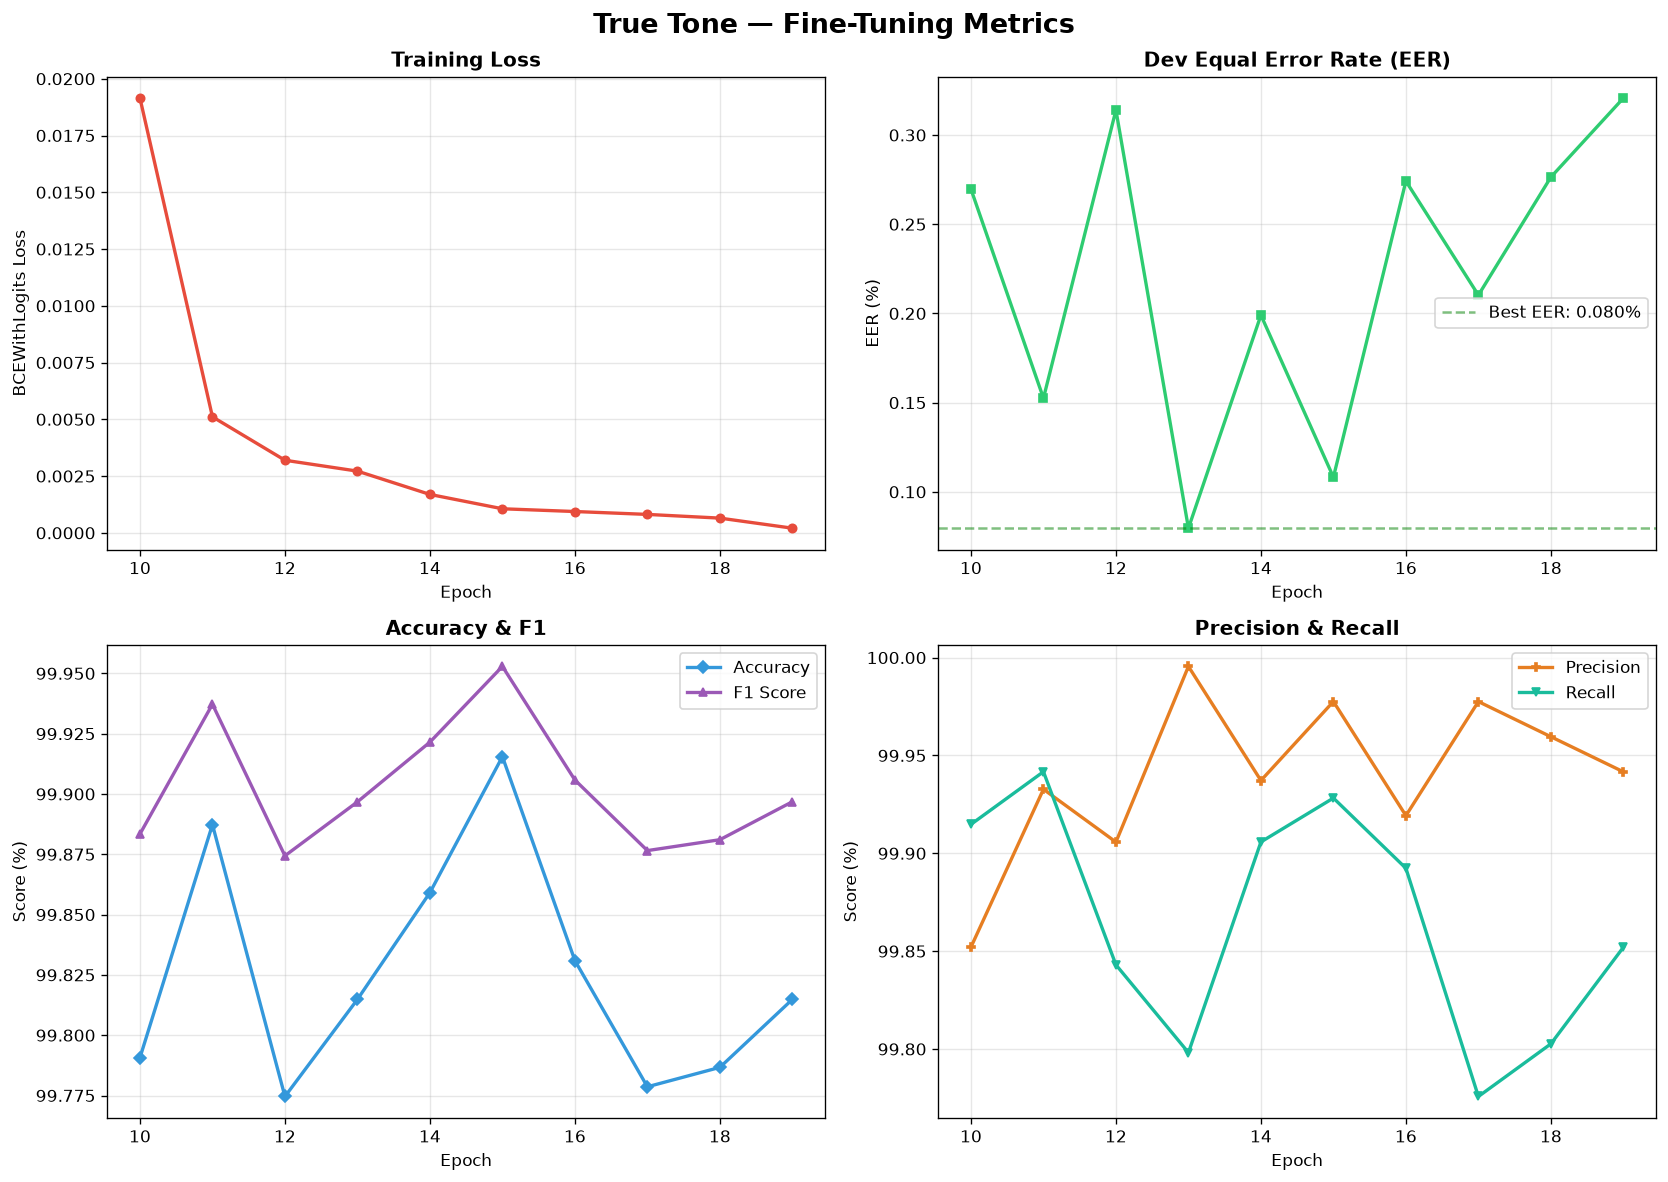

📊 Plot saved to: C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih\models\finetune_metrics.png


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('True Tone — Fine-Tuning Metrics', fontsize=16, fontweight='bold')

epochs_list = history['epoch']

# 1. Train Loss
ax = axes[0, 0]
ax.plot(epochs_list, history['train_loss'], 'o-', color='#e74c3c', linewidth=2, markersize=5)
ax.set_title('Training Loss', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('BCEWithLogits Loss')
ax.grid(True, alpha=0.3)

# 2. Dev EER
ax = axes[0, 1]
ax.plot(epochs_list, history['dev_eer'], 's-', color='#2ecc71', linewidth=2, markersize=5)
ax.axhline(y=best_eer*100, color='green', linestyle='--', alpha=0.5, label=f'Best EER: {best_eer*100:.3f}%')
ax.set_title('Dev Equal Error Rate (EER)', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('EER (%)')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Accuracy & F1
ax = axes[1, 0]
ax.plot(epochs_list, history['dev_accuracy'], 'D-', color='#3498db', linewidth=2, markersize=5, label='Accuracy')
ax.plot(epochs_list, history['dev_f1'], '^-', color='#9b59b6', linewidth=2, markersize=5, label='F1 Score')
ax.set_title('Accuracy & F1', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Score (%)')
ax.legend()
ax.grid(True, alpha=0.3)

# 4. Precision & Recall
ax = axes[1, 1]
ax.plot(epochs_list, history['dev_precision'], 'P-', color='#e67e22', linewidth=2, markersize=5, label='Precision')
ax.plot(epochs_list, history['dev_recall'], 'v-', color='#1abc9c', linewidth=2, markersize=5, label='Recall')
ax.set_title('Precision & Recall', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Score (%)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'finetune_metrics.png'), bbox_inches='tight')
plt.show()
print(f"📊 Plot saved to: {os.path.join(CHECKPOINT_DIR, 'finetune_metrics.png')}")

## 9 · 🔬 Post-Training Evaluation

Run the final model on bundled sample files + detailed confusion matrix.

In [10]:
# Reload the best checkpoint for evaluation
best_ckpt = torch.load(best_checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(best_ckpt['model_state_dict'])
model.eval()

eval_thresh = best_ckpt.get('optimal_threshold', 0.40)
print(f"📦 Loaded best checkpoint (Epoch {best_ckpt['epoch']}, EER {best_ckpt['best_eer']*100:.4f}%)")
print(f"   Using threshold: {eval_thresh:.4f}")

# ── Test on bundled sample files ──
print("\n" + "─" * 50)
print("Reference Sample Tests")
print("─" * 50)

samples_dir = os.path.join(PROJECT_ROOT, 'samples')
for fname in ['sample_bonafide_human_voice.flac', 'sample_spoof_ai_voice.flac']:
    fpath = os.path.join(samples_dir, fname)
    if not os.path.exists(fpath):
        print(f"  ⚠️  {fname} not found, skipping")
        continue

    feat = torch.from_numpy(extract_lfcc(fpath)).unsqueeze(0).to(device)
    with torch.no_grad():
        prob = torch.sigmoid(model(feat)).item()

    verdict = 'AUTHENTIC HUMAN ✅' if prob < eval_thresh else 'SYNTHETIC SPOOF 🚨'
    print(f"  {fname}")
    print(f"    Spoof probability: {prob*100:.2f}%  →  {verdict}")

📦 Loaded best checkpoint (Epoch 13, EER 0.0796%)
   Using threshold: 0.1555

──────────────────────────────────────────────────
Reference Sample Tests
──────────────────────────────────────────────────
  sample_bonafide_human_voice.flac
    Spoof probability: 0.01%  →  AUTHENTIC HUMAN ✅
  sample_spoof_ai_voice.flac
    Spoof probability: 99.99%  →  SYNTHETIC SPOOF 🚨



Computing full dev set confusion matrix...


Eval:   0%|          | 0/389 [00:00<?, ?it/s]

C:\Users\bipul\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


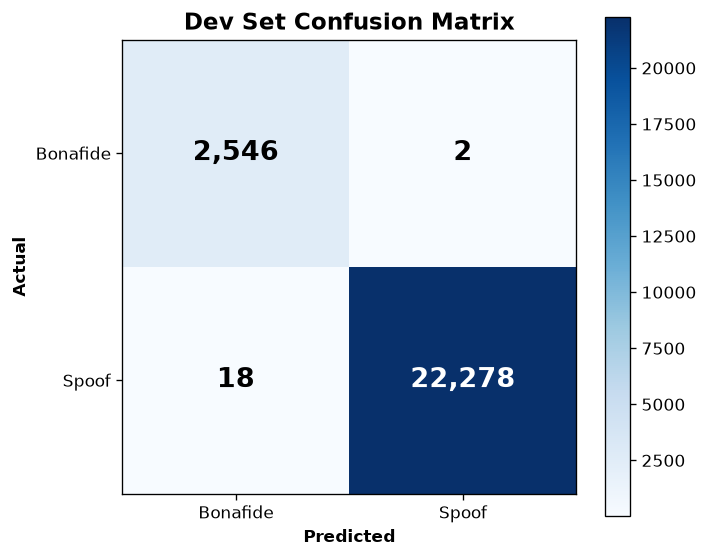


📋 Final Dev Metrics:
   EER         : 0.0796%
   Accuracy    : 99.92%
   F1 Score    : 99.96%
   Opt. Thresh : 0.1555


In [11]:
# ── Full Dev Set Confusion Matrix ──
print("\nComputing full dev set confusion matrix...")

all_labels = []
all_probs = []

with torch.no_grad():
    for feats, labels in tqdm(dev_loader, desc='Eval', leave=False):
        feats = feats.to(device)
        with torch.amp.autocast('cuda', enabled=use_amp):
            logits = model(feats)
            probs = torch.sigmoid(logits)
        all_probs.extend(probs.cpu().numpy().tolist())
        all_labels.extend(labels.numpy().tolist())

y_true = np.array(all_labels)
y_scores = np.array(all_probs)
y_pred = (y_scores >= eval_thresh).astype(int)

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues', interpolation='nearest')
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Bonafide', 'Spoof'])
ax.set_yticklabels(['Bonafide', 'Spoof'])
ax.set_xlabel('Predicted', fontweight='bold')
ax.set_ylabel('Actual', fontweight='bold')
ax.set_title('Dev Set Confusion Matrix', fontsize=14, fontweight='bold')

for i in range(2):
    for j in range(2):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color=color, fontsize=16, fontweight='bold')

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, 'confusion_matrix.png'), bbox_inches='tight')
plt.show()

final_eer, final_thresh = compute_eer(y_true, y_scores)
final_acc = accuracy_score(y_true, y_pred) * 100
final_f1  = f1_score(y_true, y_pred, zero_division=0) * 100

print(f"\n📋 Final Dev Metrics:")
print(f"   EER         : {final_eer*100:.4f}%")
print(f"   Accuracy    : {final_acc:.2f}%")
print(f"   F1 Score    : {final_f1:.2f}%")
print(f"   Opt. Thresh : {final_thresh:.4f}")

## 10 · 🎤 Quick Inference on Any Audio File

Drop any `.wav` / `.flac` / `.mp3` file path below to get an instant spoof probability.

In [12]:
# ═══════════════════════════════════════
# 🔽 CHANGE THIS PATH TO YOUR AUDIO FILE
# ═══════════════════════════════════════
TEST_AUDIO_PATH = os.path.join(PROJECT_ROOT, 'samples', 'sample_bonafide_human_voice.flac')


if os.path.exists(TEST_AUDIO_PATH):
    model.eval()
    feat = torch.from_numpy(extract_lfcc(TEST_AUDIO_PATH)).unsqueeze(0).to(device)

    t0 = time.time()
    with torch.no_grad():
        prob = torch.sigmoid(model(feat)).item()
    latency_ms = (time.time() - t0) * 1000

    print(f"🎤 File: {os.path.basename(TEST_AUDIO_PATH)}")
    print(f"   Spoof Probability: {prob*100:.2f}%")
    print(f"   Verdict: {'🚨 SYNTHETIC AI SPOOF' if prob >= eval_thresh else '✅ AUTHENTIC HUMAN VOICE'}")
    print(f"   Inference latency: {latency_ms:.1f} ms")
else:
    print(f"❌ File not found: {TEST_AUDIO_PATH}")
    print("   Update TEST_AUDIO_PATH above and re-run this cell.")

🎤 File: sample_bonafide_human_voice.flac
   Spoof Probability: 0.01%
   Verdict: ✅ AUTHENTIC HUMAN VOICE
   Inference latency: 5.4 ms


## 11 · 💾 Export Options

Save the model in different formats if needed.

In [13]:
# ── Save a named backup of this fine-tuned checkpoint ──
backup_name = f"finetuned_epoch{end_epoch}_eer{best_eer*100:.2f}.pt"
backup_path = os.path.join(CHECKPOINT_DIR, backup_name)

import shutil
shutil.copy2(best_checkpoint_path, backup_path)
print(f"💾 Backup saved: {backup_path}")
print(f"   Size: {os.path.getsize(backup_path) / 1024**2:.1f} MB")

💾 Backup saved: C:\Users\bipul\OneDrive\Documents\GitHub\True Tone SIH\True-Tone-sih\models\finetuned_epoch19_eer0.08.pt
   Size: 8.4 MB


In [14]:
# ── (Optional) Export to ONNX for deployment ──
# Uncomment to export:

# onnx_path = os.path.join(CHECKPOINT_DIR, 'audio_spoof_detector.onnx')
# dummy_input = torch.randn(1, 400, 60).to(device)
# model.eval()
# torch.onnx.export(
#     model, dummy_input, onnx_path,
#     input_names=['audio_features'],
#     output_names=['spoof_logit'],
#     dynamic_axes={'audio_features': {0: 'batch_size'}},
#     opset_version=14
# )
# print(f"📦 ONNX exported: {onnx_path}")

---

## 🧪 Tips for Better Results

| Tip | Details |
|---|---|
| **Lower LR for fine-tuning** | Use `1e-4` or `5e-5` instead of `3e-4` to avoid catastrophic forgetting |
| **More epochs** | If EER is still dropping, increase `EPOCHS` and re-run Section 7 |
| **Freeze early layers** | Freeze CNN layers to only fine-tune LSTM + Attention (see below) |
| **Add more data** | Put new audio in `data/my_dataset/real/` and `data/my_dataset/spoof/` |
| **Augment telephony** | Use `train_scaled_dataset.py` to add G.711 / bandpass variants |

### Freeze CNN layers (optional)
```python
# Add this BEFORE the training loop to freeze the CNN front-end:
for name, param in model.named_parameters():
    if 'conv' in name or 'bn' in name:
        param.requires_grad = False
        print(f"  ❄️ Frozen: {name}")
```